# Etapa 05 — Mascarar o macrófago com a cor do fundo

- Autor: Clésio Gonçalves
- Criado em: 18 nov. 2026

**Objetivo:** variação da etapa 03. A região do macrófago continua apagada, mas é preenchida com a **cor mediana do fundo do próprio recorte**, e não com preto.

| | |
|---|---|
| **Entrada** | `02_datasets_derivados/02_recortes_512/` (saída da etapa 02, com o macrófago visível) |
| **Saída** | `02_datasets_derivados/05_recortes_512_macrofago_cor_fundo/<lamina>/` |
| **Usado em** | exp13 |

**Motivação:** o retângulo preto cria bordas artificiais muito fortes, que não existem nas imagens reais e podem atrair falsos positivos. Também deixa o recorte com uma grande área sem informação, que muda a estatística de cor que o modelo vê. Preencher com a cor do fundo deixa a região apagada parecida com uma área vazia da lâmina.

**Lógica (igual à etapa 03, exceto pela cor):**
1. Identifica as bboxes da classe `macrophage` em cada recorte.
2. Calcula a cor mediana (por canal) dos pixels **fora** de todas as bboxes `macrophage`. Se não sobrar nenhum pixel fora, usa a mediana do recorte inteiro.
3. Pinta cada bbox `macrophage` com essa cor.
4. Remove do `.txt` as anotações `macrophage` e `inside-macrophage` e mantém `leishmania` e `Non-macrophages`.
5. Copia o `obj.names` sem alteração.

As anotações resultantes são idênticas às da etapa 03; só muda a imagem.

# Importações e parâmetros

In [1]:
import os
import shutil
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from pathlib import Path
from PIL import Image, ImageDraw

In [2]:
diretorio_raiz = Path("/mnt/arquivos/Doutorado")
diretorio_derivados = os.path.join(diretorio_raiz, "02_datasets_derivados")

# Entrada: recortes 512x512 com o macrófago visível (etapa 02)
diretorio_recortes_entrada = os.path.join(diretorio_derivados, "02_recortes_512")

# Saída: recortes com a região do macrófago preenchida com a cor do fundo
diretorio_recortes_saida = os.path.join(diretorio_derivados, "05_recortes_512_macrofago_cor_fundo")

extensao = '.png'

with open(os.path.join(diretorio_recortes_entrada, "obj.names")) as f:
    classes = [linha.strip() for linha in f]
indice_macrofago = classes.index('macrophage')
indice_inside = classes.index('inside-macrophage')
classes_removidas = {indice_macrofago, indice_inside}
print(f"Classes: {classes}")

Classes: ['Non-macrophages', 'macrophage', 'leishmania', 'inside-macrophage']


## 1. Funções

In [3]:
# Lê um arquivo de anotação YOLO e retorna lista de (classe, xc, yc, w, h) em pixels
def le_anotacoes(txt_path, largura_img, altura_img):
    boxes = []
    if not os.path.isfile(txt_path):
        return boxes
    with open(txt_path) as f:
        for linha in f:
            linha = linha.strip()
            if not linha:
                continue
            classe_id, xc, yc, w, h = linha.split()
            boxes.append((int(classe_id), float(xc) * largura_img, float(yc) * altura_img,
                          float(w) * largura_img, float(h) * altura_img))
    return boxes


def canto_superior_inferior(xc, yc, w, h):
    return xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2


# Cor mediana dos pixels fora de todas as bboxes de macrófago
def cor_do_fundo(img, boxes_macrofago):
    rgb = np.asarray(img.convert('RGB'))
    fora = np.ones(rgb.shape[:2], dtype=bool)
    for _, xc, yc, w, h in boxes_macrofago:
        x1, y1, x2, y2 = canto_superior_inferior(xc, yc, w, h)
        fora[max(int(y1), 0):int(np.ceil(y2)) + 1, max(int(x1), 0):int(np.ceil(x2)) + 1] = False
    pixels = rgb[fora] if fora.any() else rgb.reshape(-1, 3)
    return tuple(int(v) for v in np.median(pixels, axis=0))


# Preenche a região de cada bbox de macrófago com a cor do fundo
def mascara_macrofagos(img, boxes_macrofago):
    if not boxes_macrofago:
        return img, None
    cor = cor_do_fundo(img, boxes_macrofago)
    img = img.convert('RGB').copy()
    desenho = ImageDraw.Draw(img)
    for _, xc, yc, w, h in boxes_macrofago:
        desenho.rectangle(list(canto_superior_inferior(xc, yc, w, h)), fill=cor)
    return img, cor


# Remove só as anotações de macrophage/inside-macrophage (igual à etapa 03)
def filtra_anotacoes(boxes, tamanho_img):
    boxes_macrofago = [b for b in boxes if b[0] == indice_macrofago]
    novas = [(c, xc / tamanho_img, yc / tamanho_img, w / tamanho_img, h / tamanho_img)
             for c, xc, yc, w, h in boxes if c not in classes_removidas]
    return novas, boxes_macrofago

## 2. Gerar os recortes

In [4]:
if os.path.isdir(diretorio_recortes_saida) and os.listdir(diretorio_recortes_saida):
    print("Os recortes com cor de fundo já foram gerados. Geração ignorada.")
else:
    os.makedirs(diretorio_recortes_saida, exist_ok=True)
    total = 0
    total_sem_anotacao = 0
    for lamina in sorted(os.listdir(diretorio_recortes_entrada)):
        pasta_entrada = os.path.join(diretorio_recortes_entrada, lamina)
        if not os.path.isdir(pasta_entrada):
            continue
        pasta_saida = os.path.join(diretorio_recortes_saida, lamina)
        os.makedirs(pasta_saida, exist_ok=True)
        n = 0
        for arquivo in sorted(os.listdir(pasta_entrada)):
            if not arquivo.endswith(extensao):
                continue
            nome_base = os.path.splitext(arquivo)[0]
            with Image.open(os.path.join(pasta_entrada, arquivo)) as img:
                largura, altura = img.size
                boxes = le_anotacoes(os.path.join(pasta_entrada, f"{nome_base}.txt"), largura, altura)
                anotacoes, boxes_macrofago = filtra_anotacoes(boxes, largura)
                recorte, _ = mascara_macrofagos(img, boxes_macrofago)
                recorte.save(os.path.join(pasta_saida, arquivo))
            with open(os.path.join(pasta_saida, f"{nome_base}.txt"), "w") as f:
                for classe_id, xc, yc, w, h in anotacoes:
                    f.write(f"{classe_id} {xc:.6f} {yc:.6f} {w:.6f} {h:.6f}\n")
            if not anotacoes:
                total_sem_anotacao += 1
            n += 1
        print(f"Lâmina '{lamina}': {n} recortes processados.")
        total += n
    shutil.copy(os.path.join(diretorio_recortes_entrada, "obj.names"), diretorio_recortes_saida)
    print(f"\nTotal: {total} recortes gerados em '{diretorio_recortes_saida}'.")
    print(f"Recortes sem nenhuma anotação restante: {total_sem_anotacao}")

Lâmina 'leish_1': 96 recortes processados.


Lâmina 'leish_2': 127 recortes processados.


Lâmina 'leish_3': 17 recortes processados.


Lâmina 'leish_4': 126 recortes processados.


Lâmina 'leish_5': 361 recortes processados.


Lâmina 'leish_7': 280 recortes processados.


Lâmina 'leish_8': 353 recortes processados.


Lâmina 'leish_9': 208 recortes processados.

Total: 1568 recortes gerados em '/mnt/arquivos/Doutorado/02_datasets_derivados/05_recortes_512_macrofago_cor_fundo'.
Recortes sem nenhuma anotação restante: 339


## 3. Conferência: as anotações devem ser idênticas às da etapa 03

In [5]:
diretorio_etapa03 = os.path.join(diretorio_derivados, "03_recortes_512_sem_macrofago")
diferentes = 0
conferidos = 0
for lamina in sorted(os.listdir(diretorio_recortes_saida)):
    pasta = os.path.join(diretorio_recortes_saida, lamina)
    if not os.path.isdir(pasta):
        continue
    for arquivo in os.listdir(pasta):
        if arquivo.endswith('.txt'):
            conferidos += 1
            with open(os.path.join(pasta, arquivo)) as a, open(os.path.join(diretorio_etapa03, lamina, arquivo)) as b:
                if a.read() != b.read():
                    diferentes += 1
print(f"{conferidos} arquivos de anotação conferidos; {diferentes} diferentes da etapa 03.")

1568 arquivos de anotação conferidos; 0 diferentes da etapa 03.


## 4. Verificação visual (linha de cima: etapa 03, preto; linha de baixo: cor do fundo)

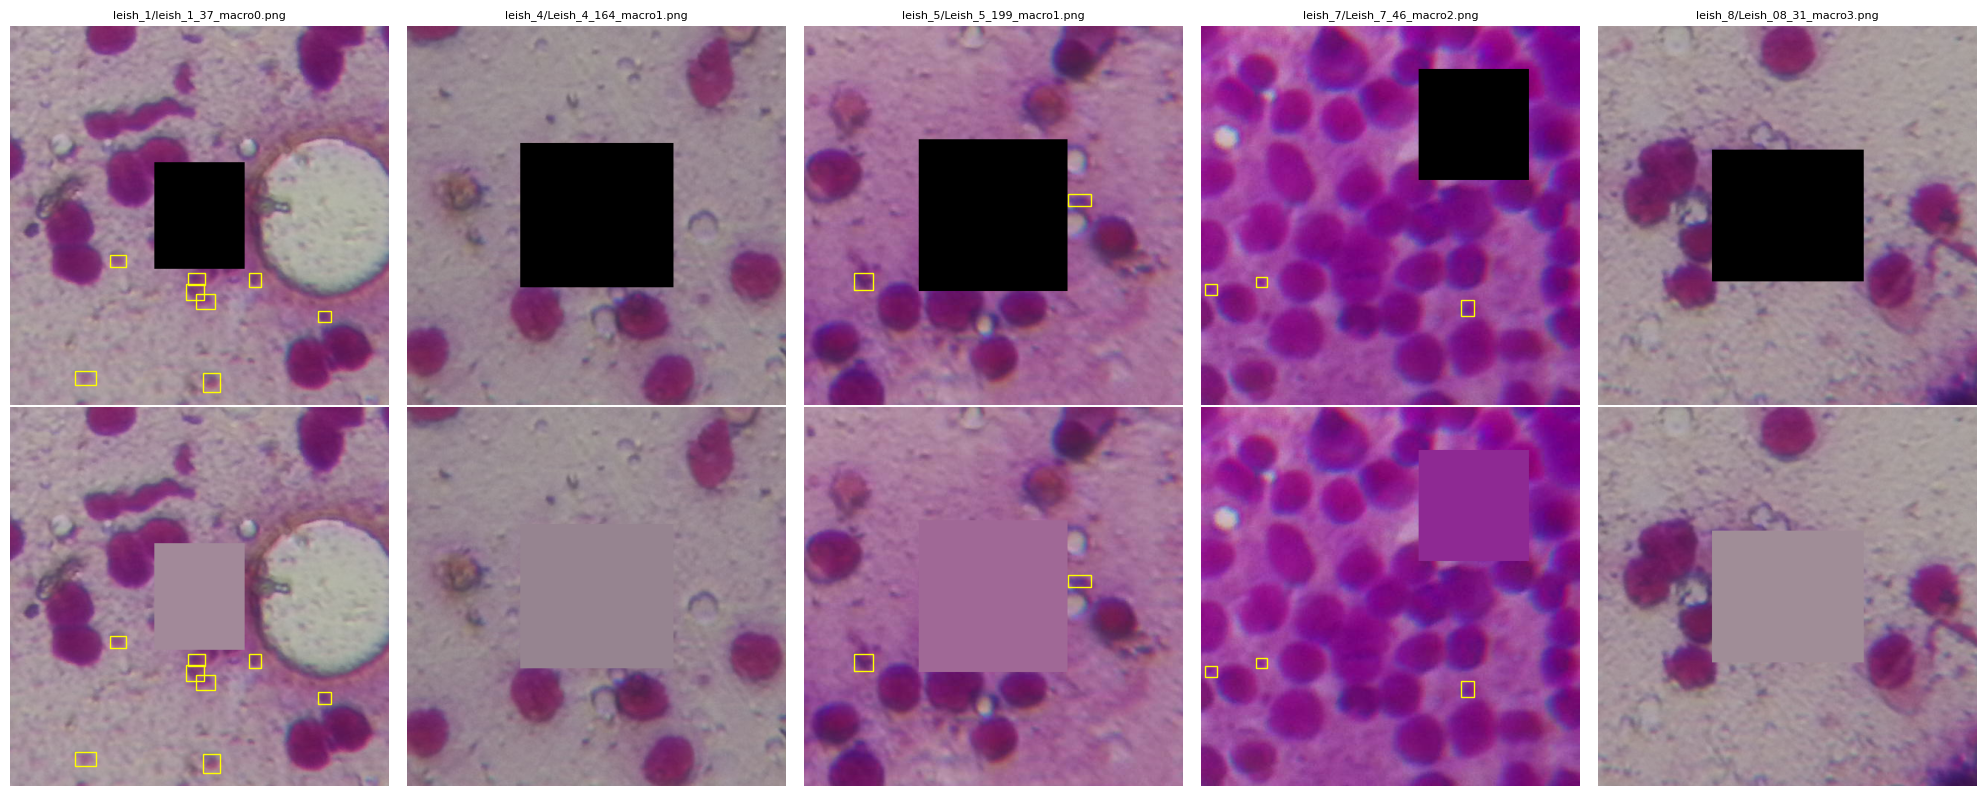

In [6]:
%matplotlib inline
amostras = []
for lamina in ['leish_1', 'leish_4', 'leish_5', 'leish_7', 'leish_8']:
    arquivos = sorted(f for f in os.listdir(os.path.join(diretorio_recortes_saida, lamina)) if f.endswith(extensao))
    amostras.append((lamina, arquivos[len(arquivos) // 2]))

fig, eixos = plt.subplots(2, len(amostras), figsize=(4 * len(amostras), 8))
for j, (lamina, arquivo) in enumerate(amostras):
    for i, diretorio in enumerate([diretorio_etapa03, diretorio_recortes_saida]):
        with Image.open(os.path.join(diretorio, lamina, arquivo)) as img:
            eixos[i, j].imshow(img)
            w_img, h_img = img.size
        with open(os.path.join(diretorio, lamina, os.path.splitext(arquivo)[0] + '.txt')) as f:
            for linha in f:
                classe_id, xc, yc, w, h = map(float, linha.split())
                eixos[i, j].add_patch(patches.Rectangle(((xc - w / 2) * w_img, (yc - h / 2) * h_img), w * w_img, h * h_img,
                                                        linewidth=1, edgecolor='yellow', facecolor='none'))
        eixos[i, j].axis('off')
    eixos[0, j].set_title(f"{lamina}/{arquivo}", fontsize=8)
plt.tight_layout()
plt.show()